# 1 · Camera characterisation and data collection

Before calibrating, I checked what the webcam actually delivers, chose the calibration target and collected the data.
Webcams silently ignore requested resolutions, crop or zoom the image, and change exposure on their own; each of these can invalidate a calibration.

> The webcam sections need captures in `data/webcam/` (mine are not published because they show my face). The saved outputs show my results; every synthetic section runs as is.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from testbench import gt

PATTERN = (9, 6)                              # inner corners of the checkerboard
WEBCAM = ROOT / "data" / "webcam"             # my captures (not published: they show my face)
FIG = ROOT / "docs" / "images"                # figures used in the README
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

## 1.1 What the webcam delivers

Measured with `calib.camera_io` (`open_camera` verifies the resolution from a real frame, `measure_fps` times 120 frames after a warm-up).
The cell below re-runs the measurement when a camera is attached (`LIVE = True`); the table shows my recorded results.

| Requested | Delivered | Aspect | Measured fps |
|---|---|---|---|
| 640×480 | 640×480 | 4:3 | 29.9 |
| 800×600 | 800×600 | 4:3 | 30.1 |
| 1280×720 | 1280×720 | 16:9 | 30.2 |
| 1920×1080 | 1920×1080 | 16:9 | 30.1 |

| Setting | Value |
|---|---|
| Camera index / backend | 0 / `cv2.CAP_ANY` |
| Autofocus | not available (fixed focus: good for calibration) |
| Exposure control | not exposed by the driver |
| Windows Studio Effects (automatic framing) | **off**: automatic framing changes zoom and crop per frame, i.e. a different $K$ for every photo |

In [2]:
LIVE = False      # set to True with a webcam attached

if LIVE:
    from calib.camera_io import open_camera, actual_resolution, measure_fps
    rows = []
    for w, h in [(640, 480), (800, 600), (1280, 720), (1920, 1080)]:
        cap = open_camera(0, w, h)
        rows.append({"requested": f"{w}x{h}", "delivered": "%dx%d" % actual_resolution(cap),
                     "fps": round(measure_fps(cap, n_frames=120), 1)})
        cap.release()
    display(pd.DataFrame(rows))

**Finding: the 4:3 modes are cropped, not just resized.** Comparing 640×480 with 1920×1080 frames of the same scene, objects at the left and right edges disappear in 640×480 while top and bottom stay the same.
The sensor keeps the central 1440×1080 region and scales it by 0.444. This matters for any reuse of the calibration in another mode: notebook 4 shows that assuming a plain resize gives a 24 % error in $f_x$.

**Decision:** calibrate **1920×1080**: full sensor width, 30 fps, and the finest sampling of the scene. With $f \approx 1250$ px at 35 cm, one pixel covers $Z/f \approx 0.28$ mm, so a ±1 mm measurement needs each click within about 1–2 px.

## 1.2 Calibration target: a phone screen

Instead of a printed board, the 9×6 checkerboard is shown full-screen on a phone (2400×1080 px, 394.6 ppi), 128 screen pixels per square:

In [3]:
square_mm = 128 / 394.6 * 25.4
print(f"square size from the screen geometry: {square_mm:.2f} mm")
print(f"square size measured with a ruler:    {66 / 8:.2f} mm  (8 squares = 66 mm)")

square size from the screen geometry: 8.24 mm
square size measured with a ruler:    8.25 mm  (8 squares = 66 mm)


| | Phone screen | Printed paper |
|---|---|---|
| Flatness | guaranteed flat glass | bends, which biases the calibration |
| Pattern | pixel-exact, sharp edges | printer scaling, toner edges |
| Risks | PWM flicker at low brightness (rolling-shutter banding), reflections, accidental zoom in the viewer | — |
| Size | small (≈ 82×58 mm board) → needs close, well-spread views | A4 |

Rules I followed: brightness ≥ 70 % (no PWM banding), no zoom in the image viewer (a zoom silently changes the square size), no reflections, frames saved as **PNG** (JPEG artefacts at sharp edges shift sub-pixel corners).

**Why the square size matters, and what it does not affect:** scaling the whole board leaves every image unchanged, so a wrong `square_mm` gives the *same* $K$, distortion and reprojection error. Only the translations and every measurement are wrong, by the same factor. Notebook 3 verifies this numerically. Only measuring a known object (the bank card) can catch this mistake.

## 1.3 Data collected

The laptop stays still and the phone moves: centre, all four image corners and edges, tilted ~40° in each direction, near (~20 cm) and far (~40 cm).
Tilted views are essential: with frontal views only, the focal length cannot be separated from the distance; corners near the image borders are what constrain the distortion.

In [4]:
from calib.detect import find_corners

folders = {"calib_1920x1080": "calibration frames",
           "second_mode_640x480": "same, in the 640x480 mode (notebook 4)",
           "apps_1920x1080": "bank card lying on the screen (notebook 5)"}

rows, all_corners = [], []
for folder, use in folders.items():
    paths = sorted((WEBCAM / folder).glob("*.png"))
    found = 0
    for p in paths:
        c = find_corners(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), PATTERN)
        if c is not None:
            found += 1
            if folder == "calib_1920x1080":
                all_corners.append(c.reshape(-1, 2))
    rows.append({"folder": folder, "use": use, "frames": len(paths), "board found": found})
pd.DataFrame(rows)

,folder,use,frames,board found
0,calib_1920x1080,calibration frames,27,27
1,second_mode_640x480,"same, in the 640x480 mode (notebook 4)",11,11
2,apps_1920x1080,bank card lying on the screen (notebook 5),12,12


**Coverage of the image by the calibration corners** (one colour per frame). Corners reach all four borders and corners of the image, which is what the distortion model needs.

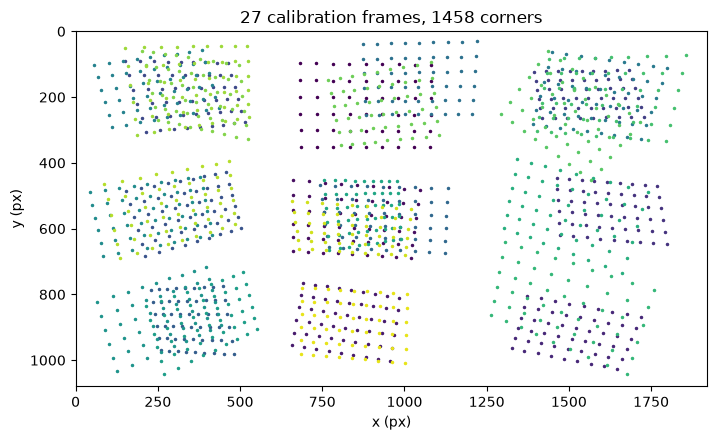

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, c in enumerate(all_corners):
    ax.plot(c[:, 0], c[:, 1], ".", ms=3, color=plt.cm.viridis(i / len(all_corners)))
ax.set_xlim(0, 1920); ax.set_ylim(1080, 0); ax.set_aspect("equal")
ax.set_title(f"{len(all_corners)} calibration frames, {sum(len(c) for c in all_corners)} corners")
ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
fig.tight_layout(); fig.savefig(FIG / "coverage.png", dpi=120); plt.show()